# 1. Amplitude amplification

A circuit succeeds with probability $a$. Repeating it until it succeeds takes $1/a$ tries. Amplitude amplification gets there in about $1/\sqrt a$ rounds instead, and its oblivious version does it for a block encoding without knowing the state it acts on. Both appear inside the circuits the later notebooks cost.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from qcost.amplify import lcu_block_encoding, oblivious_round, rounds_needed, success_after
from qcost.exact import tfim
from qcost.walk import walk_matrix

## The recipe on three qubits

$A = H^{\otimes 3}$ makes the uniform superposition; call $|101\rangle$ the good outcome. Measuring right away succeeds with $a = 1/8$. One round of amplification is
$$Q = -A\,S_0\,A^\dagger\,S_\text{good},$$
where $S_\text{good}$ flips the sign of the good states and $S_0$ the sign of $|000\rangle$. Apply $Q$ a few times and measure:

In [2]:
H1 = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
A = np.kron(np.kron(H1, H1), H1)
good = np.zeros(8, dtype=bool)
good[0b101] = True

theta = np.arcsin(np.sqrt(1 / 8))
for m in range(6):
    print(f"m = {m}: success {success_after(A, good, m):.4f}   sin^2((2m+1) theta) = {np.sin((2*m+1)*theta)**2:.4f}")
print("rounds_needed(1/8) =", rounds_needed(1 / 8))

m = 0: success 0.1250   sin^2((2m+1) theta) = 0.1250
m = 1: success 0.7812   sin^2((2m+1) theta) = 0.7813
m = 2: success 0.9453   sin^2((2m+1) theta) = 0.9453
m = 3: success 0.3301   sin^2((2m+1) theta) = 0.3301
m = 4: success 0.0122   sin^2((2m+1) theta) = 0.0122
m = 5: success 0.5480   sin^2((2m+1) theta) = 0.5480
rounds_needed(1/8) = 2


Two rounds take the success probability from 0.125 to 0.945, and the numbers follow $\sin^2((2m+1)\theta)$ with $\sin^2\theta = a$ exactly [Brassard, Høyer, Mosca, Tapp, [quant-ph/0005055](https://arxiv.org/abs/quant-ph/0005055), Thm. 2]. A third round overshoots: the probability falls to 0.33.

## What one round does

The state $A|0\rangle = \sin\theta\,|\text{good}\rangle + \cos\theta\,|\text{bad}\rangle$ lives in a plane. $S_\text{good}$ reflects it about $|\text{bad}\rangle$; $-A S_0 A^\dagger$ reflects it about $A|0\rangle$. Two reflections make a rotation by twice the angle between their axes, $2\theta$. So after $m$ rounds the angle from $|\text{bad}\rangle$ is $(2m+1)\theta$, and $m \approx \pi/(4\theta)$ rounds reach $\pi/2$. For small $a$, $\theta \approx \sqrt a$:

In [3]:
print(f"{'a':>8} {'tries 1/a':>12} {'rounds':>8}  (each round uses A twice)")
for a in (1e-2, 1e-4, 1e-6):
    print(f"{a:8.0e} {1/a:12.0f} {rounds_needed(a):8d}")

       a    tries 1/a   rounds  (each round uses A twice)
   1e-02          100        7
   1e-04        10000       78
   1e-06      1000000      785


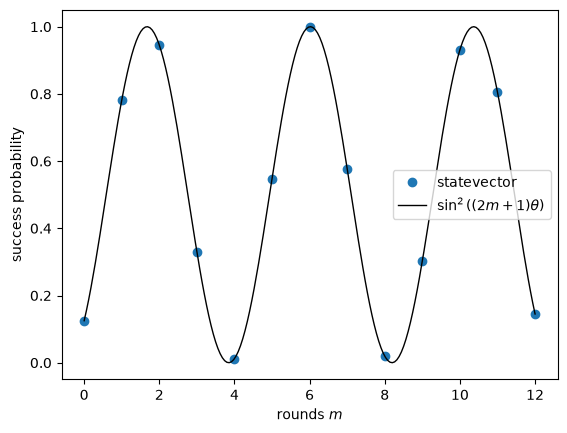

In [4]:
ms = np.arange(0, 13)
plt.plot(ms, [success_after(A, good, m) for m in ms], "o", label="statevector")
mm = np.linspace(0, 12, 200)
plt.plot(mm, np.sin((2 * mm + 1) * theta) ** 2, "k-", lw=1, label=r"$\sin^2((2m+1)\theta)$")
plt.xlabel("rounds $m$")
plt.ylabel("success probability")
plt.legend();

The rotation keeps going: stopping at the right round needs $a$ to be known. When it is, the last round can be shortened so the success is exactly 1 [same paper, Sec. 2.1].

## The oblivious version

A block encoding of an operator $V$ is a unitary $U$ with
$$U\,|0\rangle|\psi\rangle = \sin\theta\,|0\rangle V|\psi\rangle + \cos\theta\,|\Phi^\perp\rangle,$$
where $|\Phi^\perp\rangle$ has the ancilla away from $|0\rangle$. Measuring the ancilla in $|0\rangle$ applies $V$, with probability $\sin^2\theta$. Plain amplification would need to reflect about $U|0\rangle|\psi\rangle$, so it would need to know $|\psi\rangle$. If $V$ is unitary, then $\sin\theta$ is the same for every $|\psi\rangle$, and reflecting about the ancilla alone, $R = 2|0\rangle\langle 0| - 1$, does the job: $-U R U^\dagger R U$ is one round [Berry, Childs, Cleve, Kothari, Somma, [arXiv:1312.1414](https://arxiv.org/abs/1312.1414), Lemma 3.6]. When $\sin\theta = 1/2$, one round lands exactly on $V|\psi\rangle$.

Build one. Take $V = e^{i\varphi X} = \cos\varphi\, I + i\sin\varphi\, X$ and write it as a linear combination of unitaries (LCU, notebook 04) whose coefficients add up to 2, so that $U$ holds $V/2$: pad with $+c\,I$ and $c\,(-I)$, which cancel.

In [5]:
phi = 0.4
c = (2 - np.cos(phi) - np.sin(phi)) / 2
X, I2 = np.array([[0, 1], [1, 0]]), np.eye(2)
U = lcu_block_encoding([np.cos(phi) + c, c, np.sin(phi) / 2, np.sin(phi) / 2], [I2, -I2, 1j * X, 1j * X])
V = np.cos(phi) * I2 + 1j * np.sin(phi) * X
print("top-left block of U equals V/2:", np.allclose(U[:2, :2], V / 2))

S = oblivious_round(U, n_anc_dim=4)
rng = np.random.default_rng(1)
for _ in range(3):
    psi = rng.normal(size=2) + 1j * rng.normal(size=2)
    psi /= np.linalg.norm(psi)
    before = np.linalg.norm((U @ np.kron([1, 0, 0, 0], psi))[:2]) ** 2
    after = np.kron([1, 0, 0, 0], psi)
    after = S @ after
    print(f"success before {before:.3f}, after one round {np.linalg.norm(after[:2])**2:.3f};",
          "state is V|psi>:", np.allclose(after[:2], V @ psi))

top-left block of U equals V/2: True
success before 0.250, after one round 1.000; state is V|psi>: True
success before 0.250, after one round 1.000; state is V|psi>: True
success before 0.250, after one round 1.000; state is V|psi>: True


Every random input goes from success $1/4$ to certainty, without the circuit knowing which input it got.

## Where it stops working

Qubitization (notebook 04) block-encodes $H/\lambda$, which is not unitary: the success amplitude $\|H|\psi\rangle\|/\lambda$ depends on $|\psi\rangle$, and the oblivious round no longer lands on the right state. The TFIM block encoding of notebook 04, one round, on an eigenstate and on a random state:

In [6]:
Hs = tfim(3, 0.7)
W = walk_matrix(Hs)
d = 2 ** Hs.n
R = -np.eye(len(W))
R[:d, :d] += 2 * np.eye(d)
U_H = R @ W  # undo the walk's reflection: U_H has H / lambda in its top-left block
print("top-left block is H/lambda:", np.allclose(U_H[:d, :d], Hs.matrix().toarray() / Hs.one_norm))
for name, psi in [("eigenstate", np.linalg.eigh(Hs.matrix().toarray())[1][:, 0]),
                  ("random", rng.normal(size=d) / np.sqrt(d))]:
    psi = psi / np.linalg.norm(psi)
    print(f"{name:10} success amplitude {np.linalg.norm(U_H[:d, :d] @ psi):.3f}")

top-left block is H/lambda: True
eigenstate success amplitude 0.680
random     success amplitude 0.463


The amplitude differs from state to state, so no fixed number of rounds is right for all of them. That is why phase estimation uses the walk operator itself, whose eigenphases $\arccos(E/\lambda)$ carry the energy, instead of trying to apply $H$.

## Where it shows up in a cost

* Preparing an equal superposition over $L$ items when $L$ is not a power of 2: a rotation shrinks the amplitude of the valid range, then one round of amplification brings it close to 1. OpenFermion's cost code for double factorization computes exactly this success probability, $\sin^2(3\arcsin(\cdot))$, when it picks the rotation's precision (notebook 08).
* Hamiltonian simulation by LCU, where the oblivious version was introduced [arXiv:1312.1414] and then used for the truncated Taylor series [Berry et al., [arXiv:1412.4687](https://arxiv.org/abs/1412.4687)].

## Exercises

1. Mark two of the eight states as good. How many rounds now, and what success do they reach?
2. With $a = 0.01$, how many uses of $A$ does amplification take, against the expected number of tries? Count both.
3. Change the padding $c$ so that the LCU coefficients add up to 3 instead of 2. Run one oblivious round: what success do you get, and why is it no longer 1?